# Analisis Deret Waktu PM2.5 Kota Surakarta

Notebook ini adalah **walkthrough reproducible** untuk proyek Analisis Data Time Series.
Pipeline utama tetap berada di `src/*.py`; notebook ini menjalankan pipeline tersebut
lalu menampilkan keluaran penting secara berurutan.

**Sumber data:** Open-Meteo Air Quality API (model CAMS global), koordinat Surakarta
`-7,5545; 110,8060`, zona waktu `Asia/Jakarta`.

**Periode model:** 8 Agustus 2022 – 21 Oktober 2024 (116 minggu, tanpa nilai hilang).
Periode setelah Oktober 2024 dikeluarkan karena terdapat patahan model CAMS
(rasio PM10/PM2.5 turun dari sekitar 1,46 menjadi 1,04).


## 1. Setup

Jalankan notebook dari folder `notebooks/` atau dari root repo. Seluruh path dihitung
relatif terhadap root repo agar tidak bergantung pada lokasi kerja.


In [1]:
from pathlib import Path
import json
import sys
import runpy

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

print("Root repo :", ROOT)
print("Python    :", sys.version.split()[0])
print("Pandas    :", pd.__version__)
assert (ROOT / "src" / "analysis.py").exists(), "analysis.py tidak ditemukan"
assert (ROOT / "data" / "processed" / "pm25_surakarta_weekly_model.csv").exists()


Root repo : D:\Kuliah\S5\ADT\Project-1
Python    : 3.11.9
Pandas    : 3.0.5


## 2. Jalankan pipeline

Cell berikut menjalankan `src/analysis.py` dari atas ke bawah. Proses ini akan
meregenerasi tabel, gambar, `results.json`, dan workbook Excel. Set `RUN_PIPELINE = False`
jika hanya ingin membaca output yang sudah ada.


In [2]:
RUN_PIPELINE = True
if RUN_PIPELINE:
    runpy.run_path(str(ROOT / "src" / "analysis.py"), run_name="__main__")
else:
    print("Pipeline dilewati; memakai output yang sudah ada.")


Observasi: 116 | Train: 104 | Test: 12
Periode: 2022-08-08 s.d. 2024-10-21


SARIMA terpilih: SARIMA(2,1,0)(1,0,0)[52] | AICc=310.63



Perbandingan model (ringkas):
                     Model    AICc  RMSE   MAE   MAPE  MASE  LB20_p
       Naive (random walk)     NaN 4.643 2.769 14.983 0.357     NaN
                     MA(3)     NaN 4.660 2.941 16.463 0.379     NaN
  SARIMA(2,1,0)(1,0,0)[52] 310.631 4.814 2.951 15.955 0.380   0.081
Fourier K=2 + ARIMA(1,1,1) 685.585 5.076 4.125 25.324 0.532   0.534
                      Holt 423.847 5.358 4.544 28.374 0.586   0.534
                       SES 419.861 5.464 4.732 29.676 0.610   0.534
              ARIMA(1,1,3) 680.267 5.708 5.085 32.149 0.655   0.871
                    AR(12) 646.329 6.572 6.187 39.469 0.797   0.994
                     MA(8)     NaN 6.687 6.162 39.458 0.794     NaN
              Holt-Winters 430.807 6.739 5.186 28.743 0.668   0.006
                 ARMA(2,3) 688.052 7.067 6.795 43.743 0.876   0.863
            Seasonal naive     NaN 8.585 6.223 36.626 0.802     NaN

Diagnostik final:
             Uji  Statistik  p_value           Interpretasi
Ljung-

## 3. Ringkasan data dan hasil utama


In [3]:
results = json.loads((ROOT / "outputs" / "results.json").read_text(encoding="utf-8"))
ringkasan = pd.DataFrame(
    [
        ("Jumlah observasi", results["n"]),
        ("Data latih", results["n_train"]),
        ("Data uji", results["n_test"]),
        ("Periode", f'{results["start"]} s.d. {results["end"]}'),
        ("Rata-rata PM2.5 (µg/m³)", round(results["mean"], 2)),
        ("Standar deviasi", round(results["std"], 2)),
        ("Model final", results["final_model"]),
        ("RMSE uji", round(results["test_rmse"], 3)),
        ("MAE uji", round(results["test_mae"], 3)),
        ("MAPE uji (%)", round(results["test_mape"], 2)),
        ("MASE uji", round(results["test_mase"], 3)),
        ("Kekuatan musiman STL", round(results["seasonal_strength"], 3)),
    ],
    columns=["Keterangan", "Nilai"],
)
display(ringkasan)


,Keterangan,Nilai
0,Jumlah observasi,116
1,Data latih,104
2,Data uji,12
3,Periode,2022-08-08 s.d. 2024-10-21
4,Rata-rata PM2.5 (µg/m³),23.82
5,Standar deviasi,8.45
6,Model final,"SARIMA(2,1,0)(1,0,0)[52]"
7,RMSE uji,4.814
8,MAE uji,2.951
9,MAPE uji (%),15.95


## 4. Eksplorasi dan dekomposisi

Gambar 1 menunjukkan seri mingguan dan pembagian latih/uji. Gambar 2 menunjukkan
dekomposisi STL aditif dengan periode 52 minggu. Amplitudo musiman relatif stabil
terhadap level, sehingga dekomposisi aditif lebih mudah ditafsirkan.


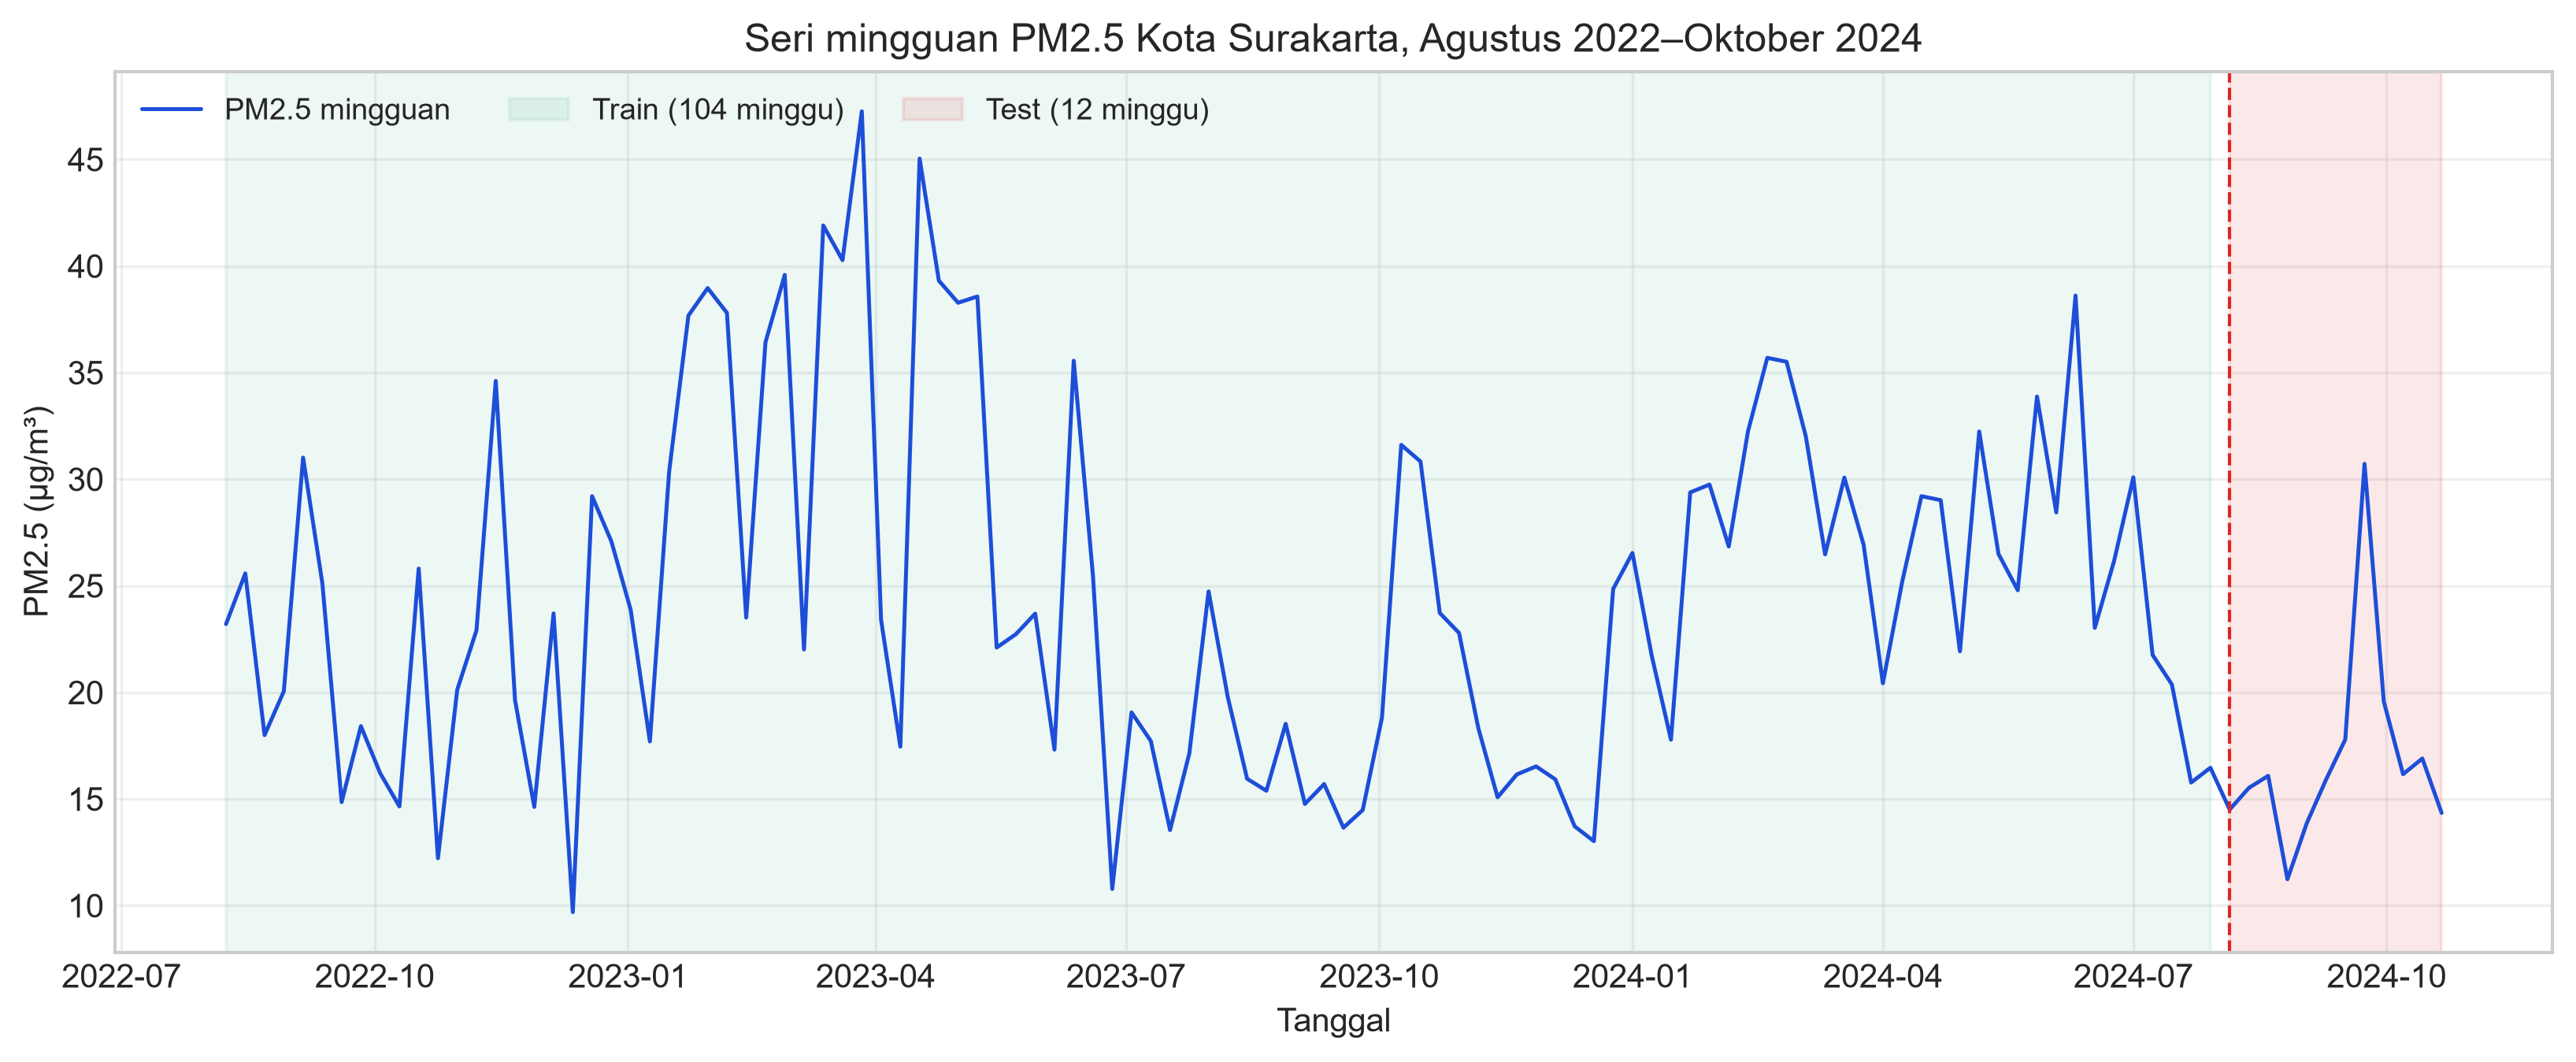

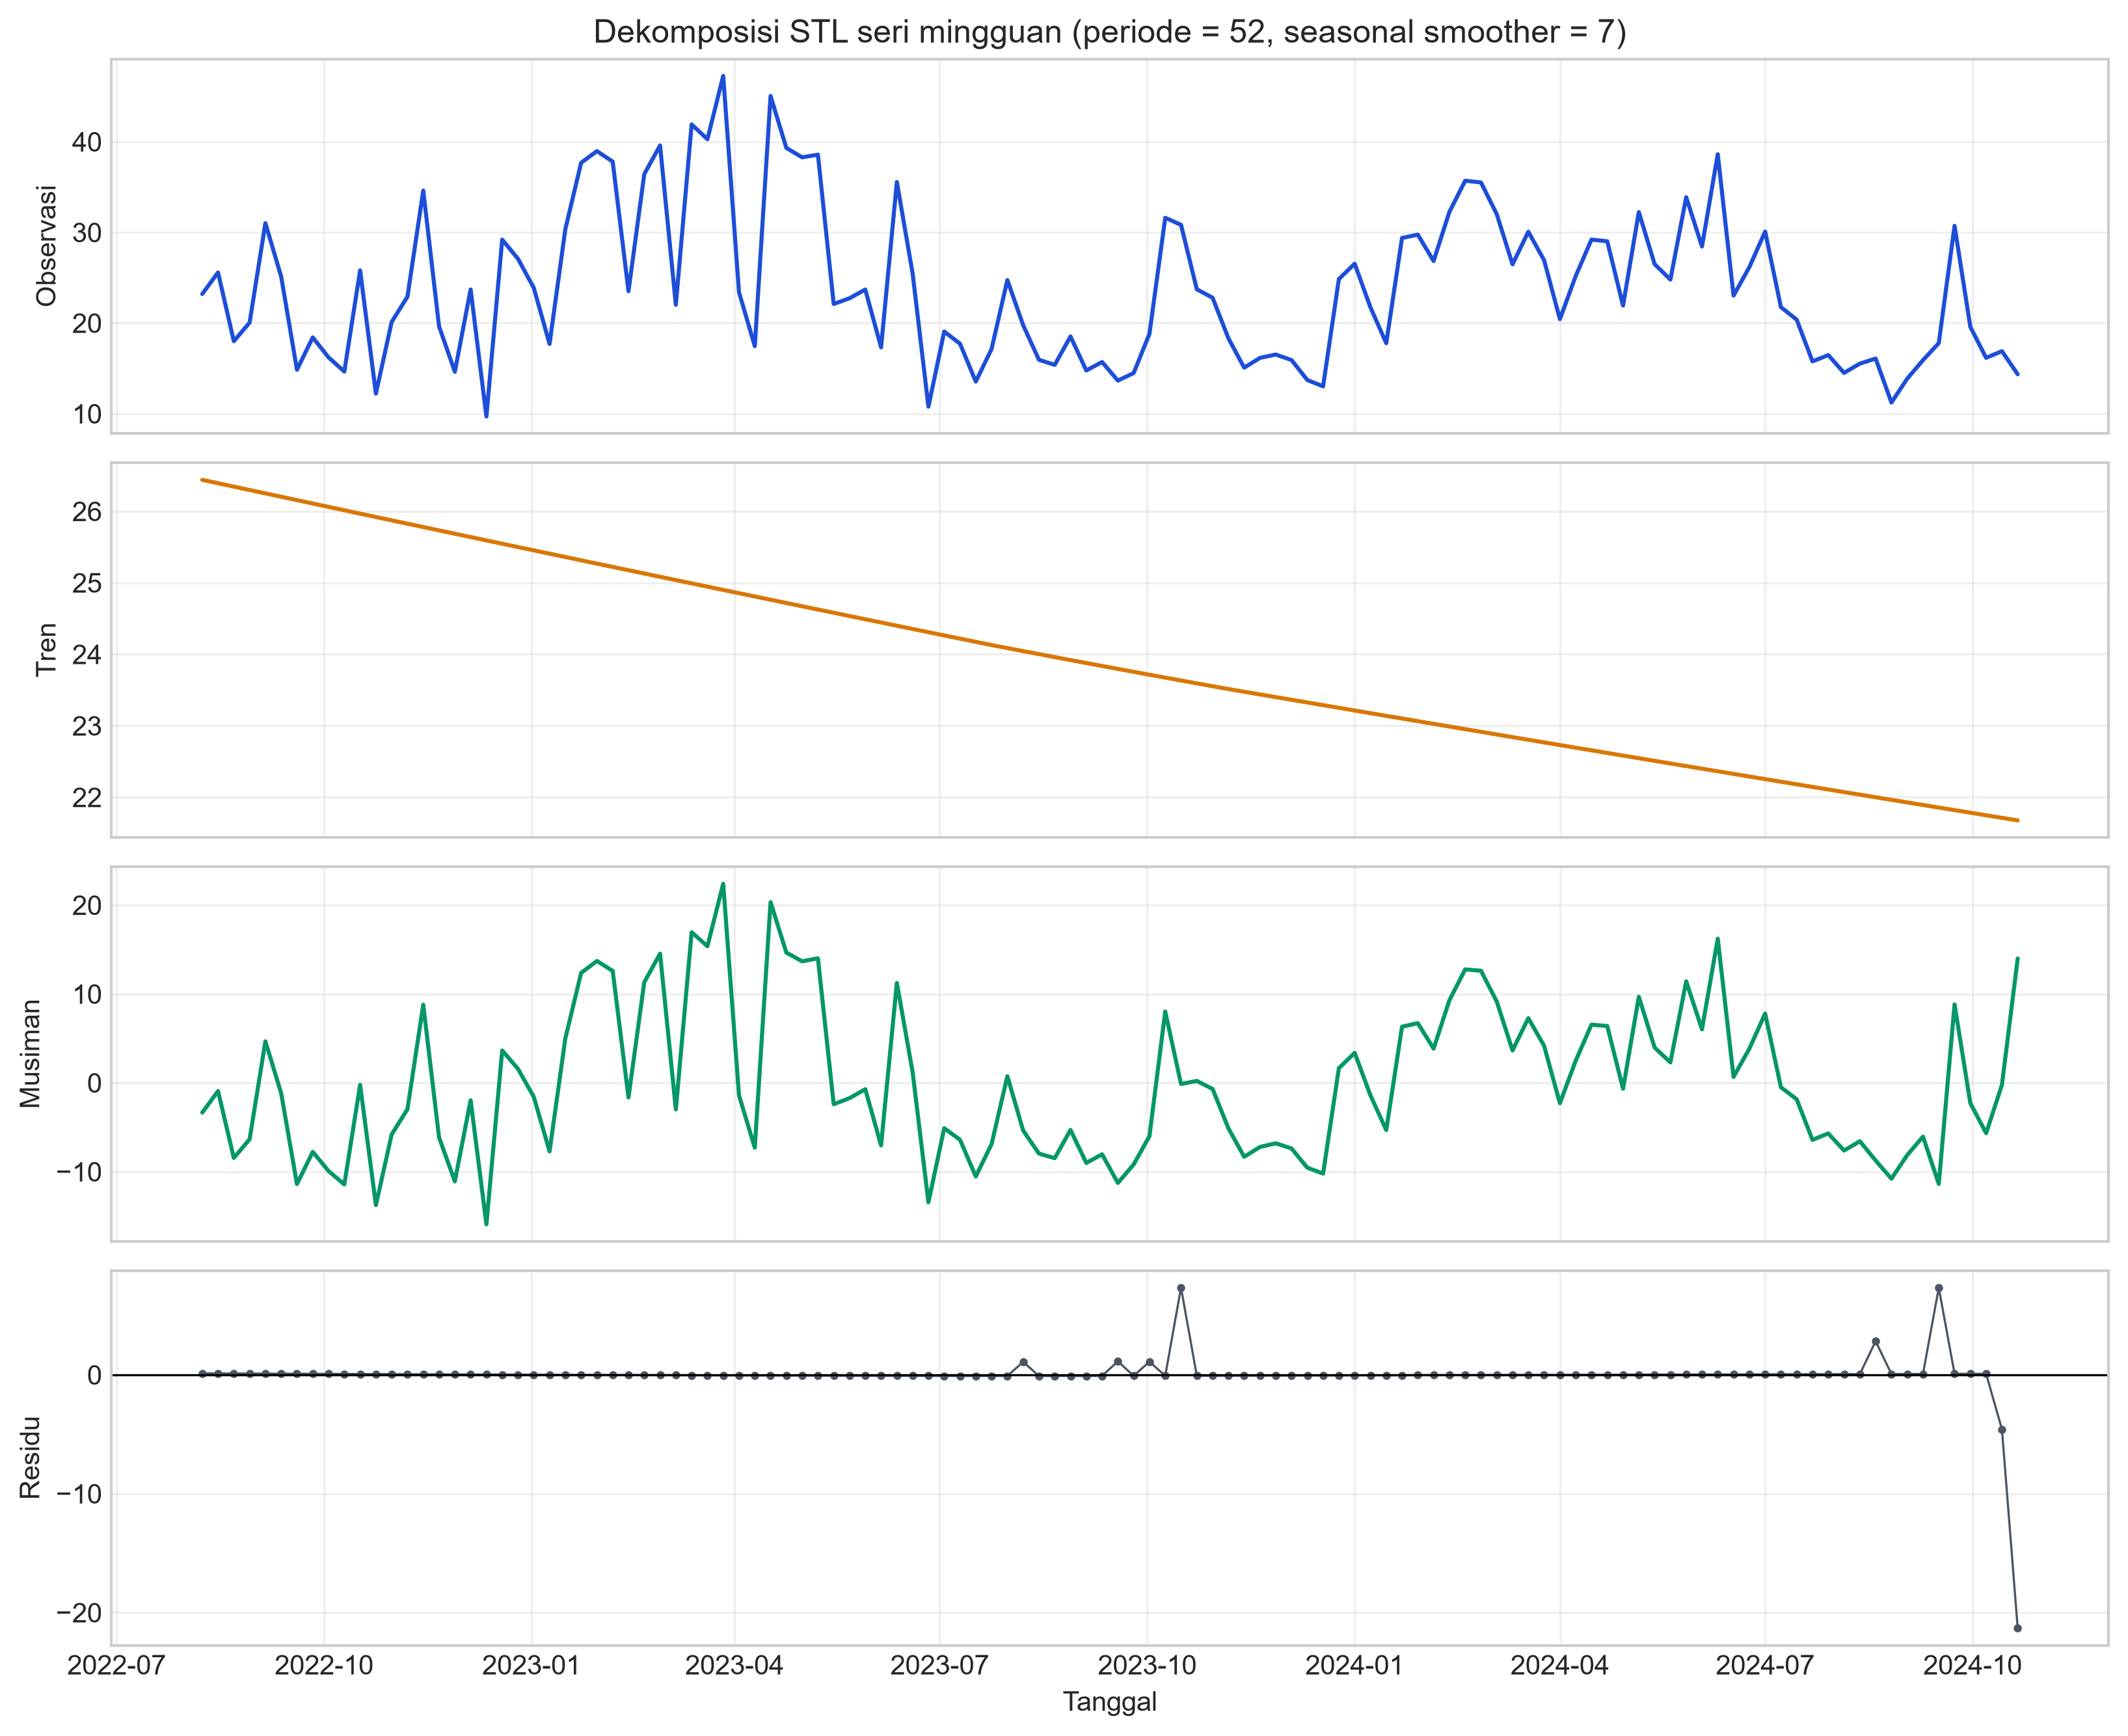

In [4]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig02_series.png"), width=900))
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig03_decomposition.png"), width=900))


In [5]:
deskriptif = pd.read_csv(ROOT / "outputs" / "tables" / "descriptive.csv")
display(deskriptif)


,Statistik,Nilai
0,Jumlah observasi,116
1,Periode awal,2022-08-08
2,Periode akhir,2024-10-21
3,Rata-rata,23.817138752052543
4,Median,22.84970238095238
5,Standar deviasi,8.446268570933459
6,Minimum,9.691666666666666
7,Kuartil 1,16.510565476190475
8,Kuartil 3,29.472619047619048
9,Maksimum,47.25595238095238


## 5. Stasioneritas

ADF pada level tidak menolak akar unit (p = 0,203), sedangkan KPSS pada level tidak
menolak stasioneritas. Karena hasilnya konflik, keputusan juga memakai ACF/PACF dan
evaluasi model. Diferensiasi pertama membuat ADF sangat signifikan; diferensiasi
musiman (lag 52) juga stasioner, tetapi hanya tersedia sekitar 2,2 siklus sehingga
`D = 1` berisiko over-differencing. Model final memakai `d = 1, D = 0` dengan
komponen AR musiman.


,Seri,Uji,Statistik,p-value,Lag,n,Kesimpulan
0,Level,ADF,-2.207808,2.034237e-01,4,111,Tidak stasioner
1,Level,KPSS,0.160796,1.000000e-01,5,116,Stasioner
2,Diferensiasi pertama,ADF,-8.667950,4.629278e-14,3,111,Stasioner
3,Diferensiasi pertama,KPSS,0.288133,1.000000e-01,47,115,Stasioner
4,Diferensiasi musiman (lag 52),ADF,-5.496995,2.112486e-06,0,63,Stasioner
5,Diferensiasi musiman (lag 52),KPSS,0.104413,1.000000e-01,3,64,Stasioner


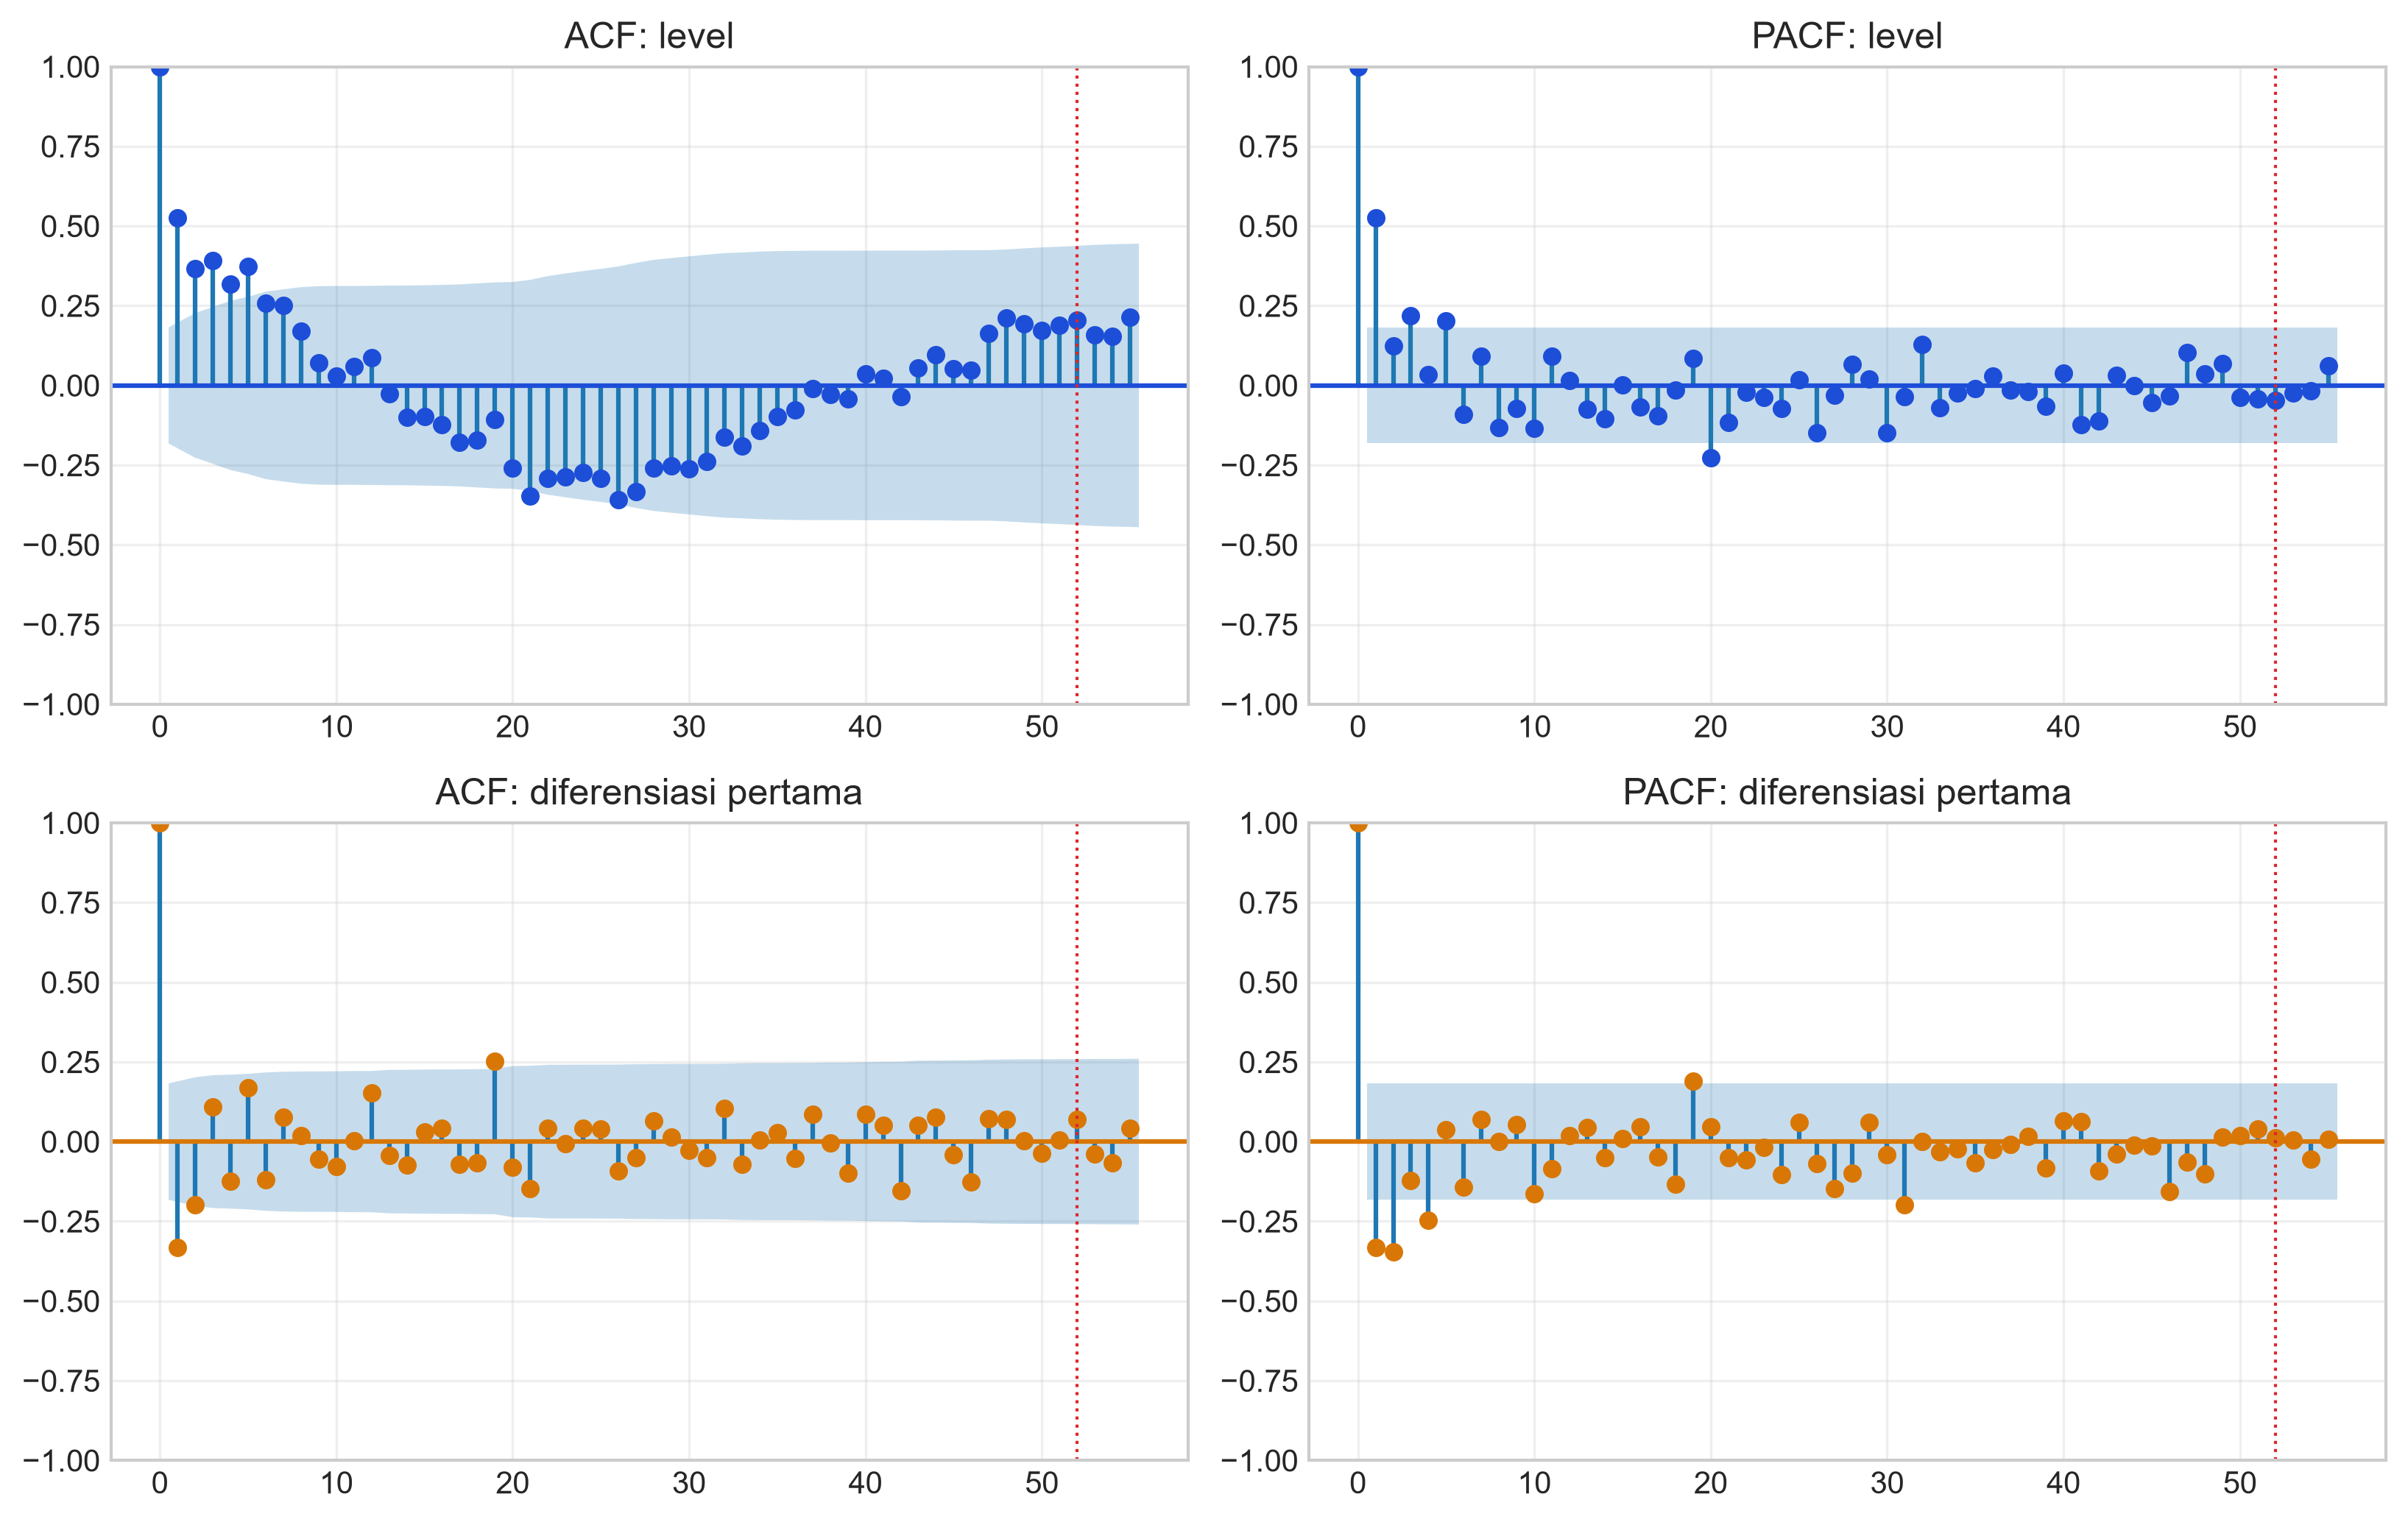

In [6]:
stasioner = pd.read_csv(ROOT / "outputs" / "tables" / "stationarity.csv")
display(stasioner)
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig05_acf_pacf.png"), width=900))


## 6. Kandidat model

Tabel berikut menampilkan kandidat teratas dari grid search. AIC/AICc hanya
dibandingkan untuk model dengan differencing dan data yang sama. Model dengan AICc
terendah belum tentu lolos diagnostik residual; karena itu pemilihan SARIMA juga
memakai Ljung-Box.


In [7]:
def top_grid(name, n=5):
    frame = pd.read_csv(ROOT / "outputs" / "tables" / name)
    return frame.head(n)

for file, label in [
    ("grid_ar.csv", "AR"),
    ("grid_arma.csv", "ARMA"),
    ("grid_arima.csv", "ARIMA"),
    ("grid_sarima.csv", "SARIMA"),
]:
    display(Markdown(f"**Kandidat {label}**"))
    display(top_grid(file))


**Kandidat AR**

,p,AIC,AICc,BIC
0,12,641.609818,646.328920,676.914858
1,11,647.644693,651.689137,680.568486
2,10,653.331548,656.760120,683.851085
3,9,659.474303,662.343868,687.566949
4,8,664.378903,666.744494,690.022385


**Kandidat ARMA**

,p,d,q,AIC,AICc,BIC,k,LB20_p,Konvergen
0,2,0,3,686.834378,688.051769,705.070569,7,0.863419,True
1,1,0,3,687.472377,688.375603,703.103398,6,0.770366,True
2,0,0,3,689.386756,690.025054,702.412607,5,0.328497,True
3,3,0,3,688.641055,690.223472,709.482416,8,0.811424,True
4,2,0,2,691.370655,692.264272,707.061378,6,0.882159,True


**Kandidat ARIMA**

,p,d,q,AIC,AICc,BIC,k,LB20_p,Konvergen
0,1,1,3,679.621908,680.267070,692.597508,5,0.871127,True
1,0,1,3,681.294889,681.720421,691.675369,4,0.765579,True
2,2,1,3,681.621667,682.534710,697.192386,6,0.872277,True
3,3,1,3,683.607955,684.838725,701.773794,7,0.852863,True
4,1,1,2,685.856872,686.277925,696.277553,4,0.885629,True


**Kandidat SARIMA**

,p,d,q,P,D,Q,s,AIC,AICc,BIC,k,LB20_p,Konvergen
0,0,1,2,0,0,1,52,305.979179,306.909412,313.463983,4,0.006668,True
1,1,1,2,0,0,1,52,305.689198,307.117769,315.045203,5,0.005617,True
2,0,1,2,1,0,1,52,306.262078,307.690650,315.618083,5,0.004889,True
3,1,1,2,1,0,1,52,306.569807,308.618587,317.797013,6,0.003778,True
4,2,1,2,0,0,1,52,307.615809,309.664590,318.843015,6,0.003238,True


## 7. Perbandingan model pada data uji

Naive random walk memiliki RMSE sedikit lebih rendah (4,643) dibanding SARIMA
(4,814), tetapi selisihnya tidak signifikan (uji Diebold-Mariano p = 0,197).
SARIMA dipilih karena memberikan struktur musiman dan interval peramalan yang
eksplisit, bukan karena lebih akurat secara signifikan.


,Model,AICc,RMSE,MAE,MAPE,MASE,LB20_p,AIC_sebanding
0,Naive (random walk),NaN,4.643,2.769,14.983,0.357,NaN,Tidak
1,MA(3),NaN,4.660,2.941,16.463,0.379,NaN,Tidak
2,"SARIMA(2,1,0)(1,0,0)[52]",310.631,4.814,2.951,15.955,0.380,0.081,Ya
3,"Fourier K=2 + ARIMA(1,1,1)",685.585,5.076,4.125,25.324,0.532,0.534,Ya
4,Holt,423.847,5.358,4.544,28.374,0.586,0.534,Tidak
5,SES,419.861,5.464,4.732,29.676,0.610,0.534,Tidak
6,"ARIMA(1,1,3)",680.267,5.708,5.085,32.149,0.655,0.871,Ya
7,AR(12),646.329,6.572,6.187,39.469,0.797,0.994,Ya
8,MA(8),NaN,6.687,6.162,39.458,0.794,NaN,Tidak
9,Holt-Winters,430.807,6.739,5.186,28.743,0.668,0.006,Tidak


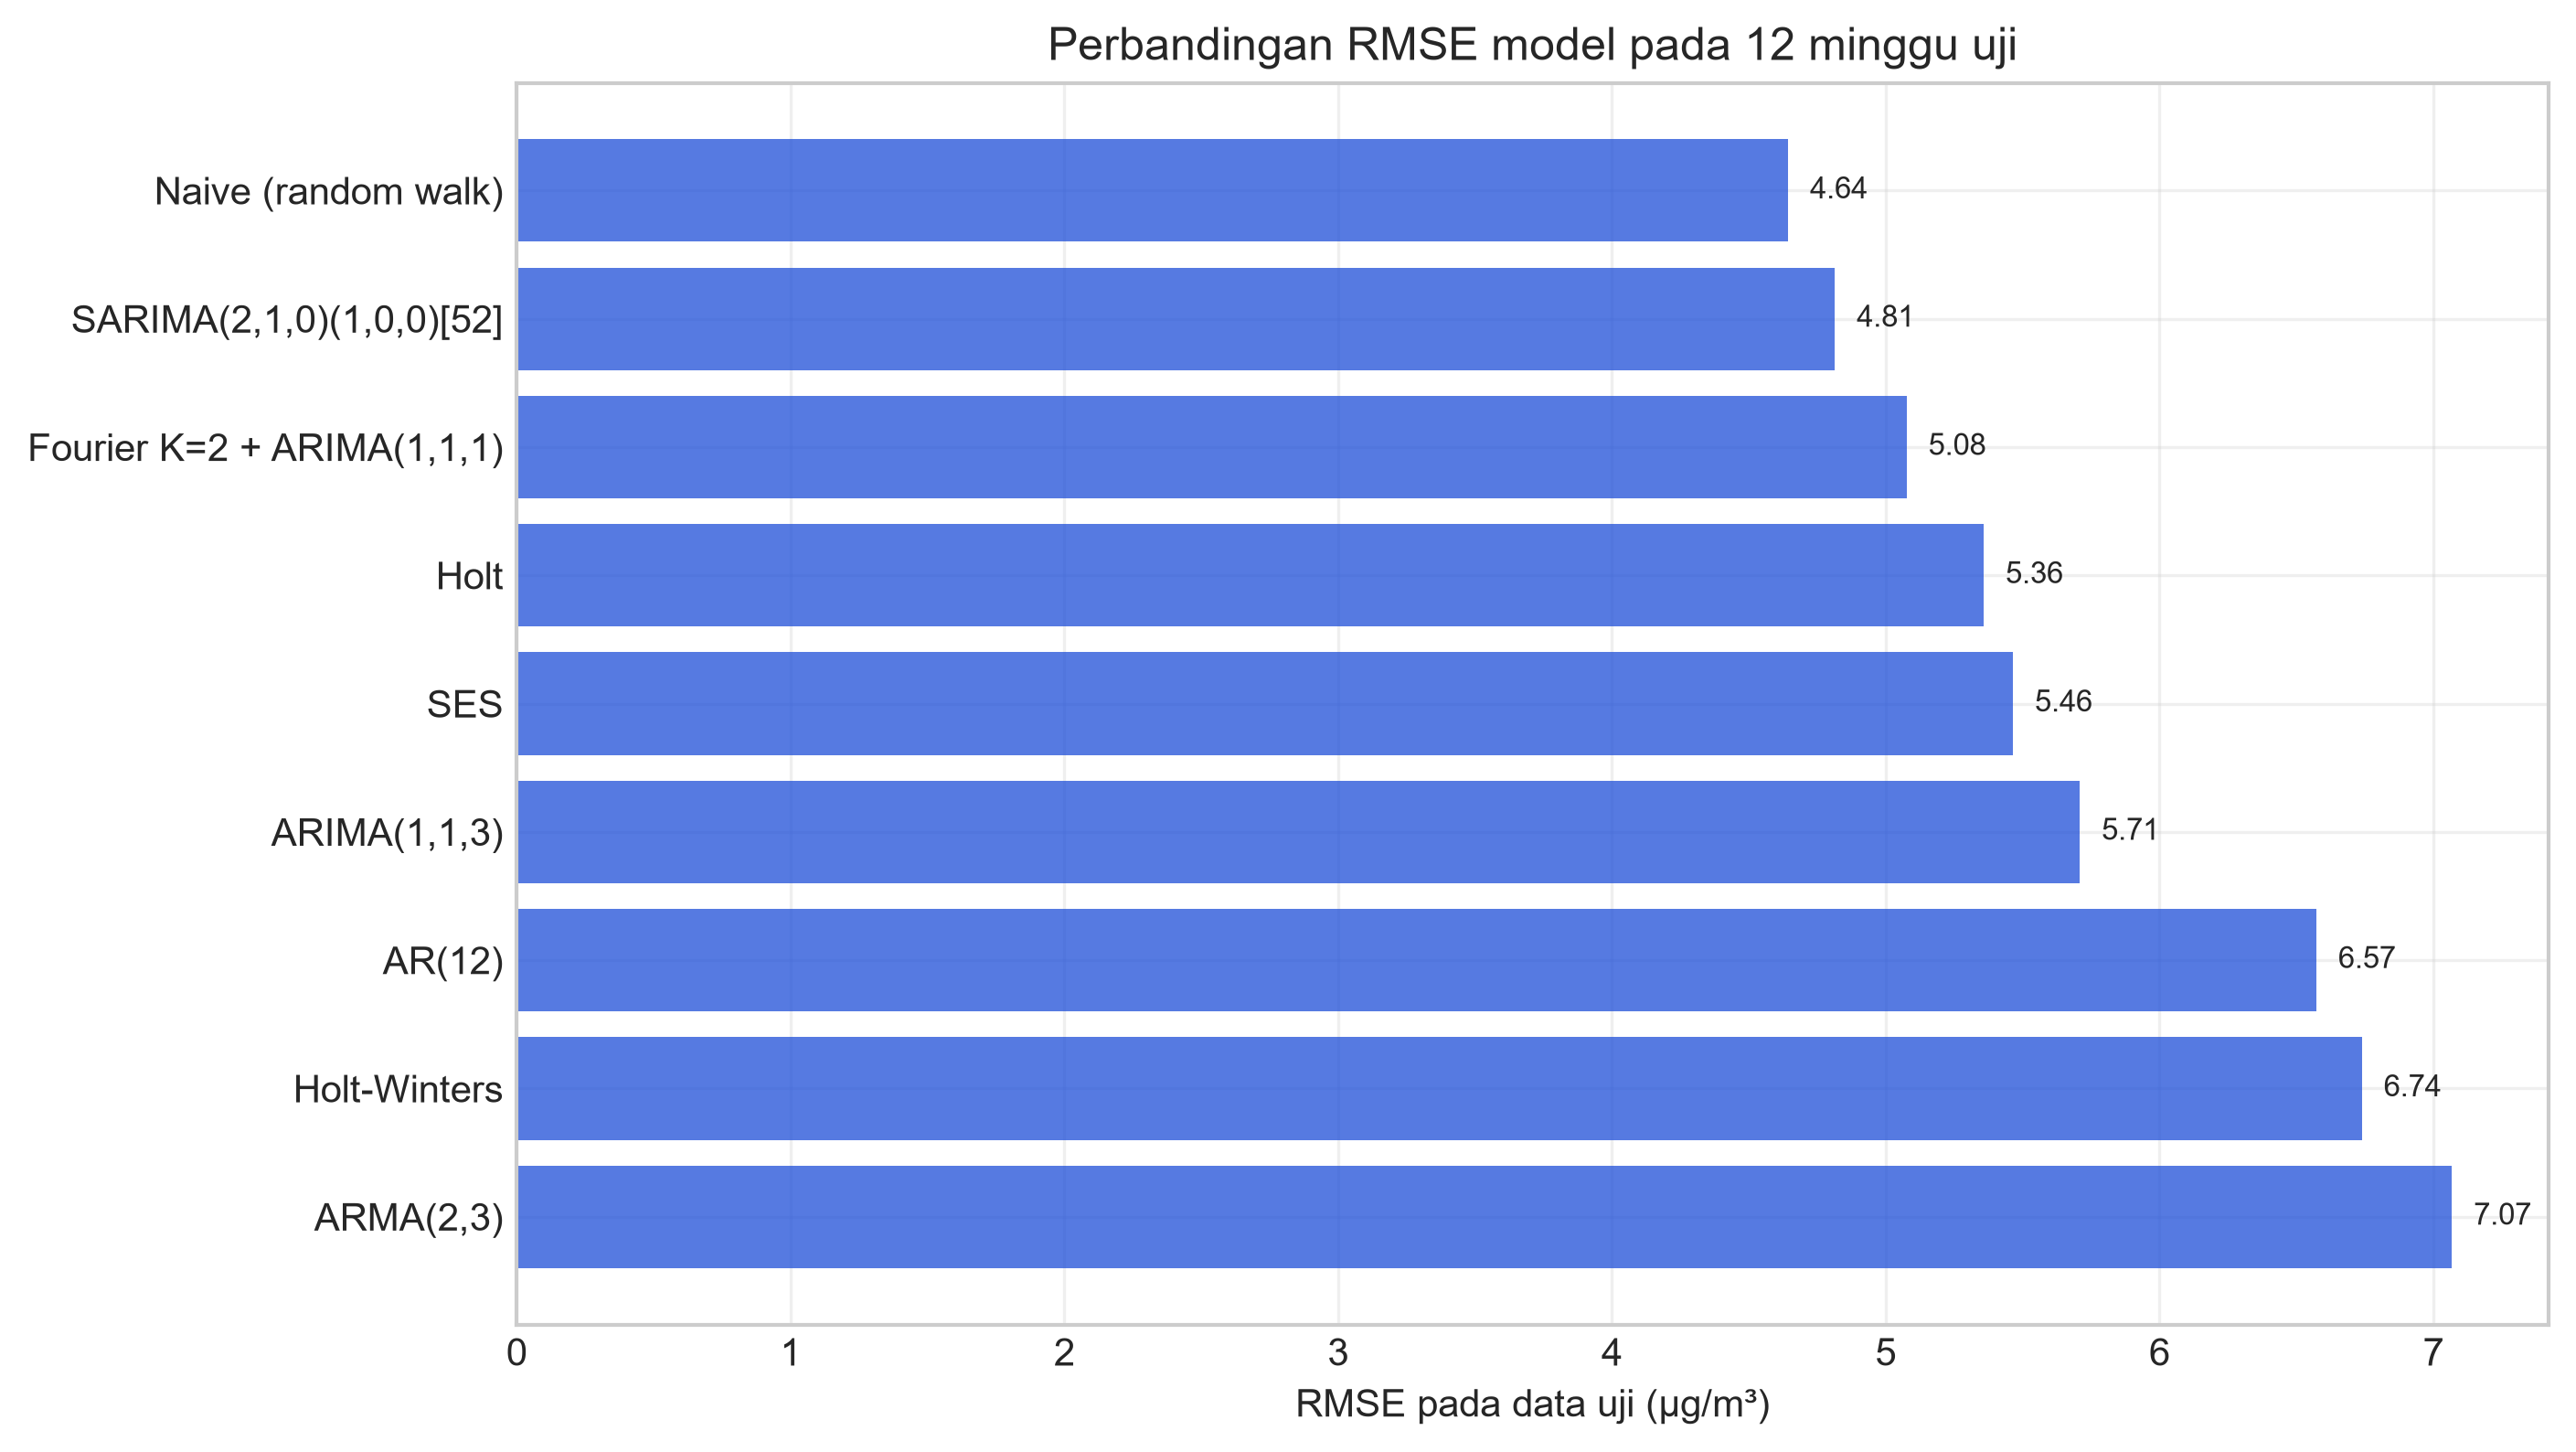

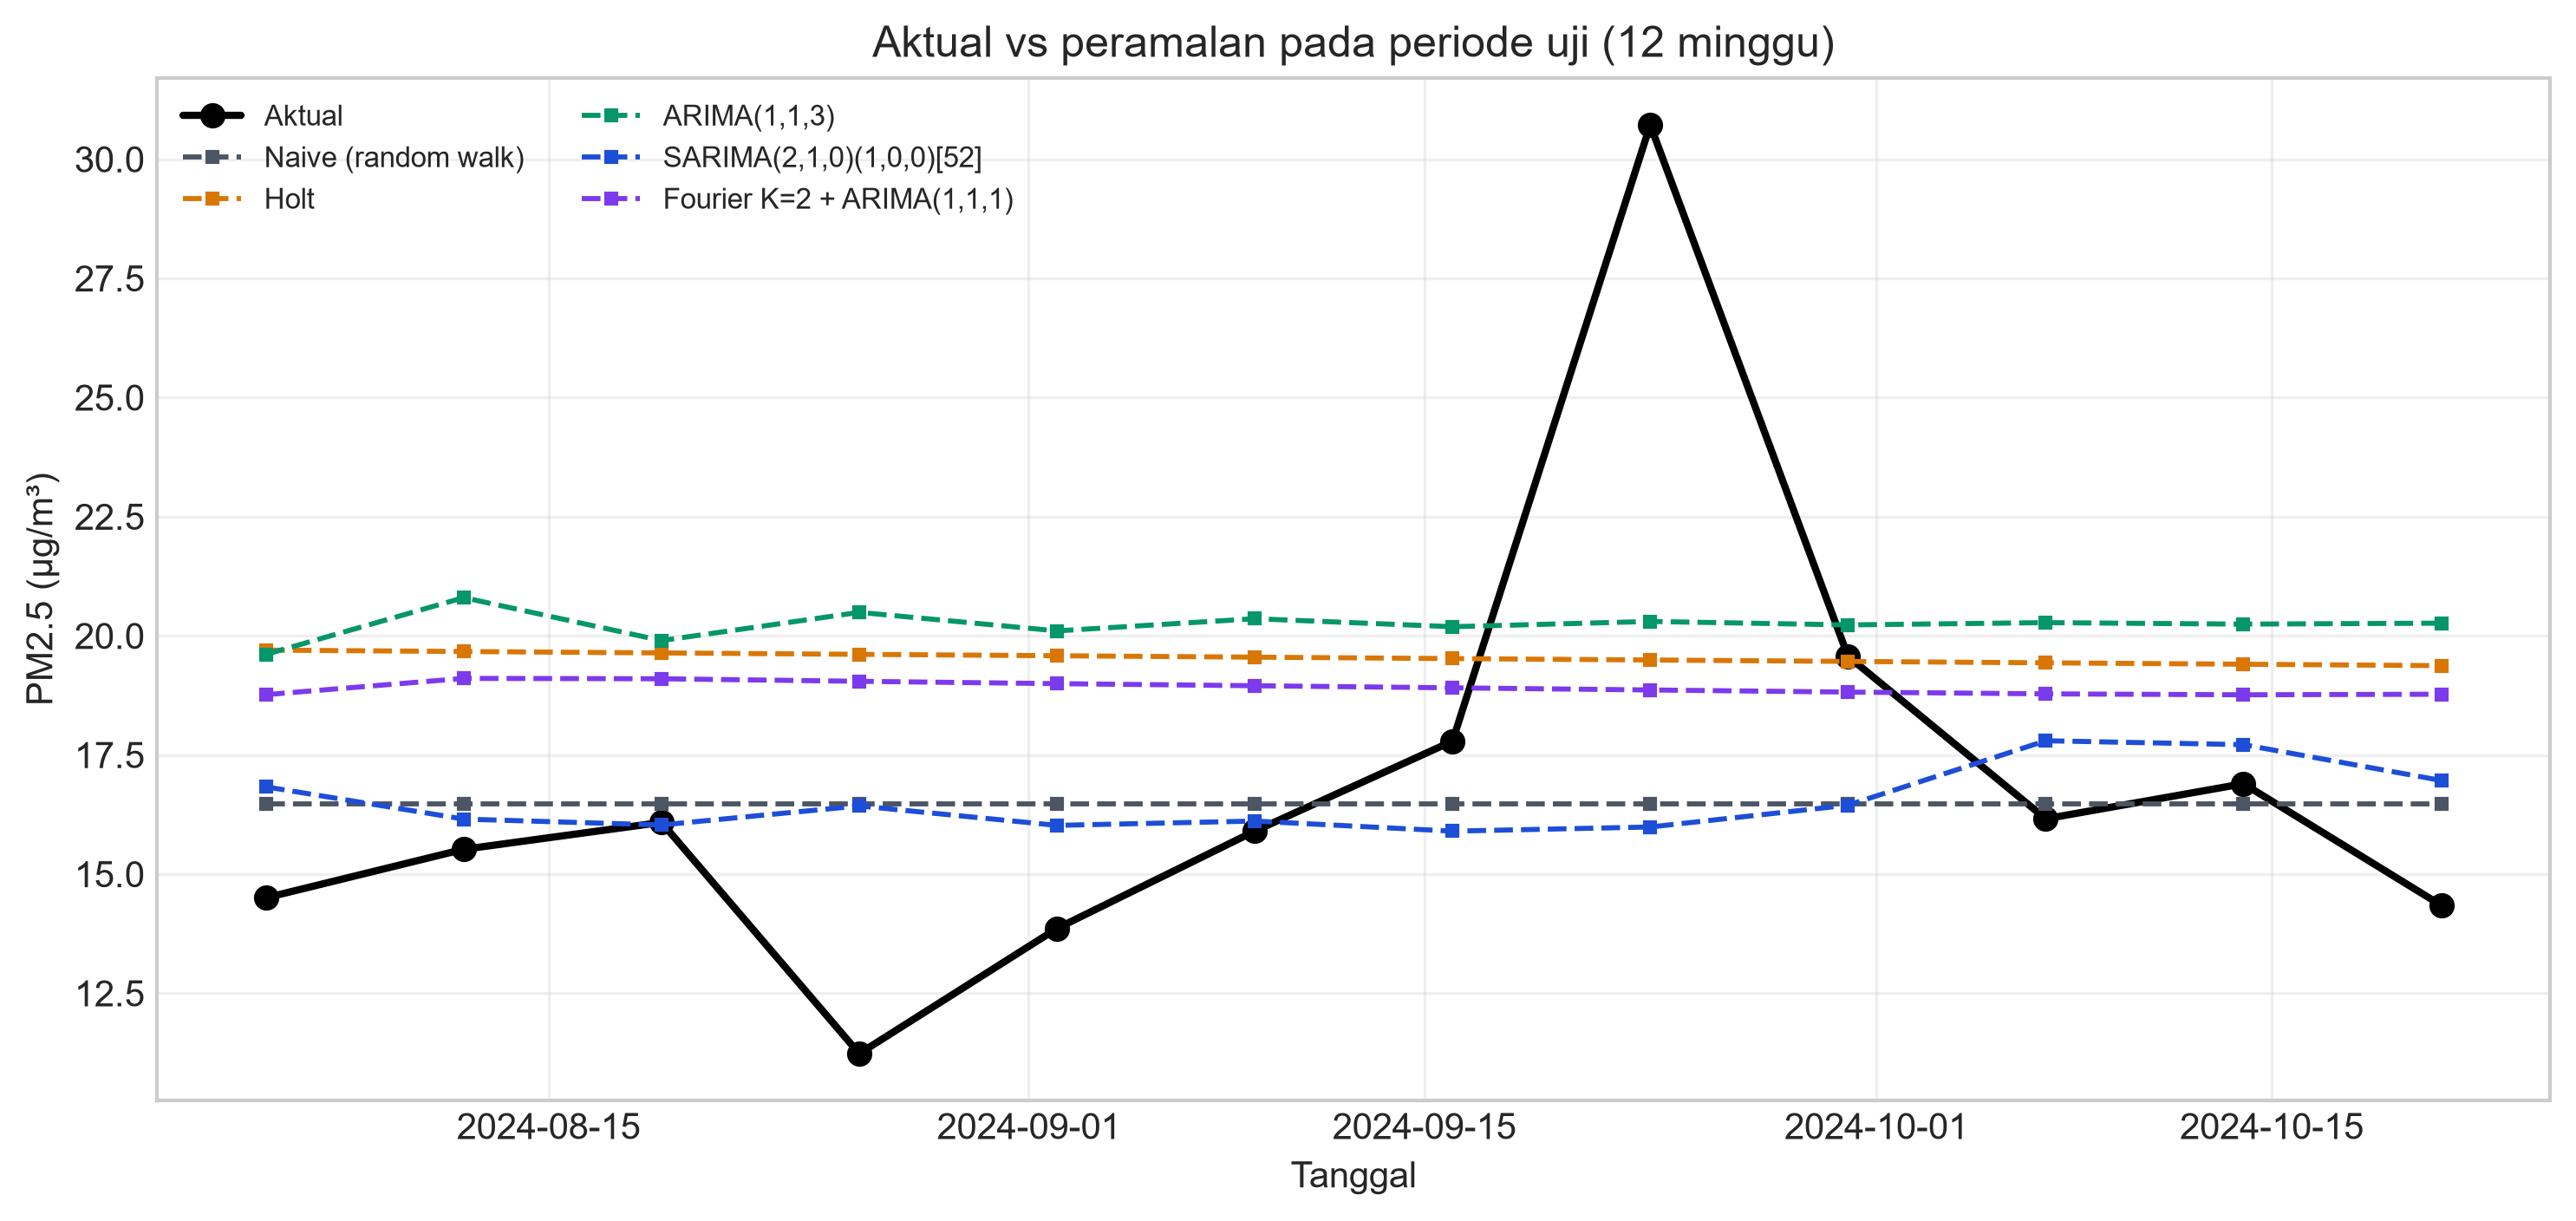

In [8]:
perbandingan = pd.read_csv(ROOT / "outputs" / "tables" / "model_comparison.csv")
kolom = ["Model", "AICc", "RMSE", "MAE", "MAPE", "MASE", "LB20_p", "AIC_sebanding"]
display(perbandingan[kolom].round(3))
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig06_model_rmse.png"), width=850))
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig07_test_forecasts.png"), width=900))


## 8. Model final dan diagnostik

Model final: **SARIMA(2,1,0)(1,0,0)[52]**. Koefisien AR(1) signifikan; AR(2) dan
AR musiman tidak signifikan pada α = 5%. Diagnostik Ljung-Box, Jarque-Bera, dan
Shapiro-Wilk lolos; ARCH LM menunjukkan heteroskedastisitas, sehingga interval
peramalan perlu ditafsirkan hati-hati.


,Parameter,Koefisien,Std_Error,z,p_value,CI_bawah,CI_atas
0,ar.L1,-0.3171,0.1302,-2.4361,0.0148,-0.5723,-0.0620
1,ar.L2,-0.1910,0.1620,-1.1791,0.2384,-0.5085,0.1265
2,ar.S.L52,0.0737,0.0892,0.8260,0.4088,-0.1012,0.2486
3,sigma2,27.7258,4.6204,6.0007,0.0000,18.6699,36.7817


,Uji,Statistik,p_value,Interpretasi
0,Ljung-Box lag 10,11.6686,0.3078,Tidak ada autokorelasi
1,Ljung-Box lag 20,28.5592,0.0968,Tidak ada autokorelasi
2,Ljung-Box lag 52,58.6006,0.2462,Tidak ada autokorelasi
3,Jarque-Bera,4.2656,0.1185,Normal
4,ARCH LM (5 lag),12.9188,0.0242,Heteroskedastik
5,Shapiro-Wilk,0.9809,0.0969,Normal
6,Durbin-Watson,2.1461,NaN,Mendekati 2 = baik


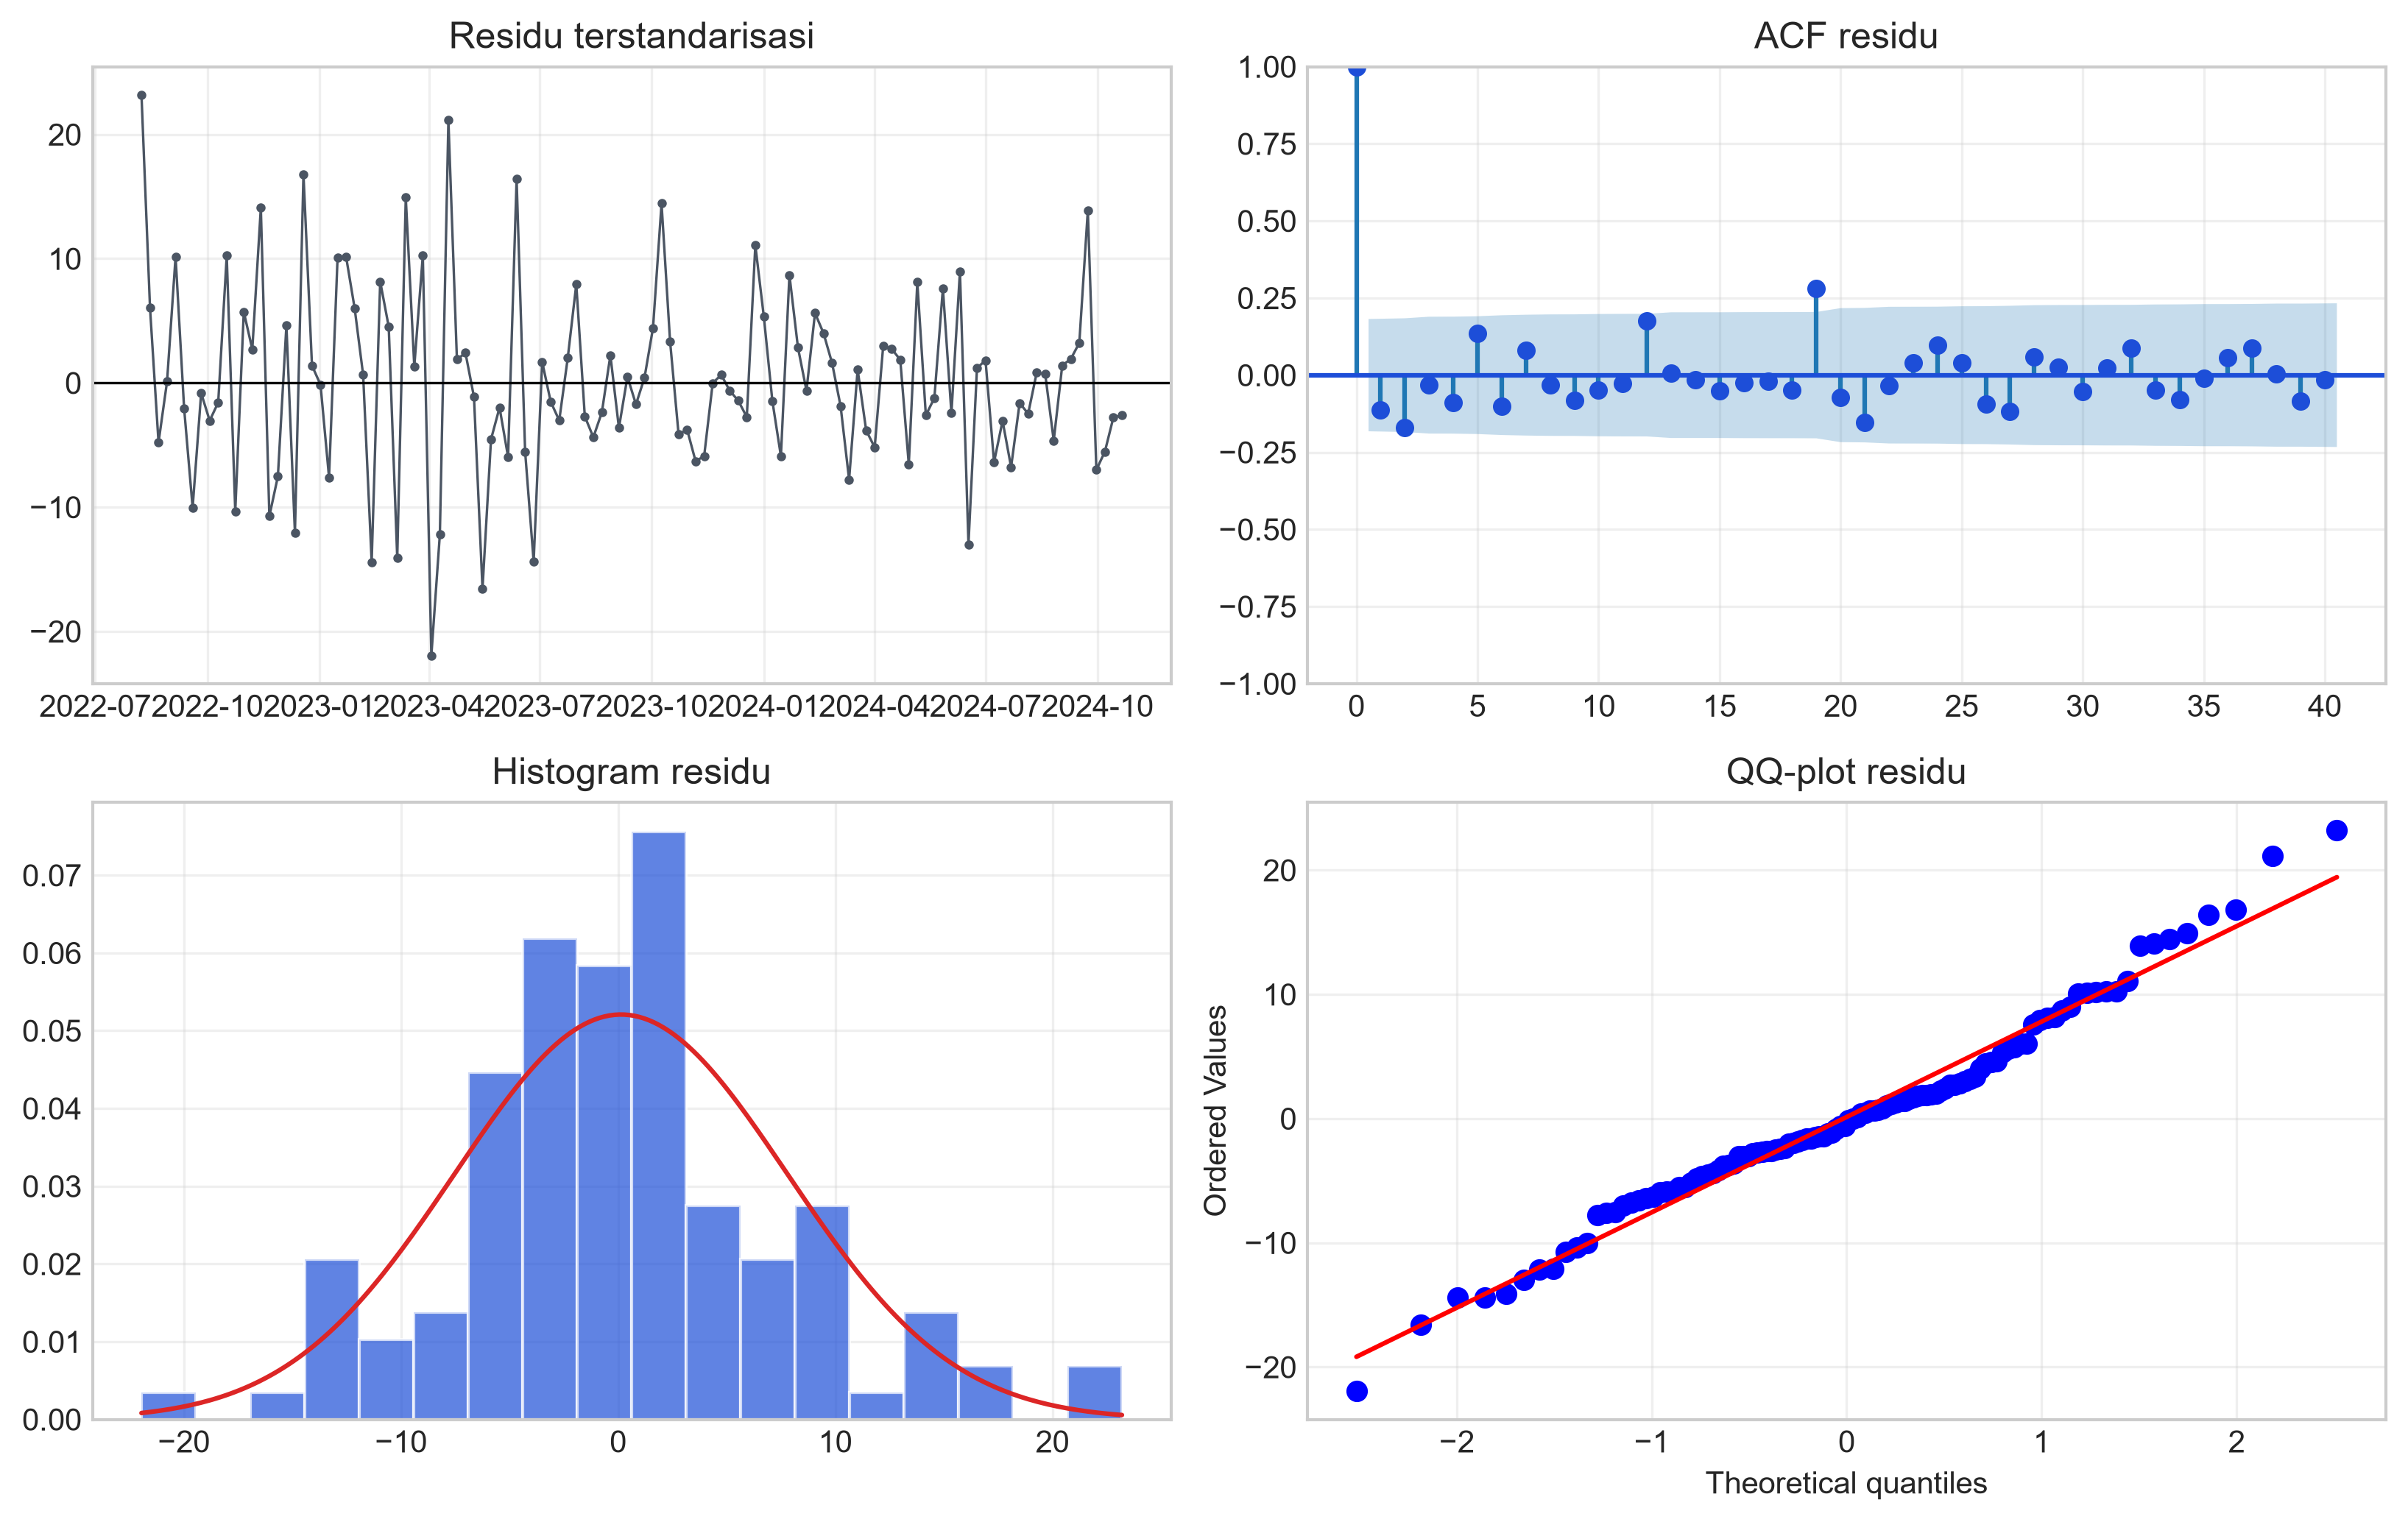

In [9]:
koefisien = pd.read_csv(ROOT / "outputs" / "tables" / "final_coefficients.csv")
diagnostik = pd.read_csv(ROOT / "outputs" / "tables" / "final_diagnostics.csv")
display(koefisien.round(4))
display(diagnostik.round(4))
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig08_residual_diagnostics.png"), width=900))


## 9. Peramalan 12 minggu

Peramalan relatif datar sekitar 14–15 µg/m³. Interval 80% dan 95% melebar cepat
karena ketidakpastian parameter dan heteroskedastisitas. Batas bawah 95% yang
negatif adalah artefak aproksimasi normal dan tidak memiliki makna fisik untuk
konsentrasi PM2.5.


,Minggu,Peramalan,Batas_bawah_80,Batas_atas_80,Batas_bawah_95,Batas_atas_95
0,2024-10-28,14.77,8.02,21.52,4.45,25.09
1,2024-11-04,14.67,6.50,22.84,2.17,27.17
2,2024-11-11,14.26,5.17,23.36,0.35,28.18
3,2024-11-18,14.35,4.16,24.55,-1.24,29.94
4,2024-11-25,14.41,3.25,25.56,-2.65,31.47
5,2024-12-02,14.35,2.35,26.35,-4.00,32.71
6,2024-12-09,14.19,1.38,27.00,-5.40,33.78
7,2024-12-16,14.14,0.57,27.71,-6.62,34.90
8,2024-12-23,15.01,0.72,29.30,-6.84,36.86
9,2024-12-30,15.13,0.16,30.11,-7.76,38.03


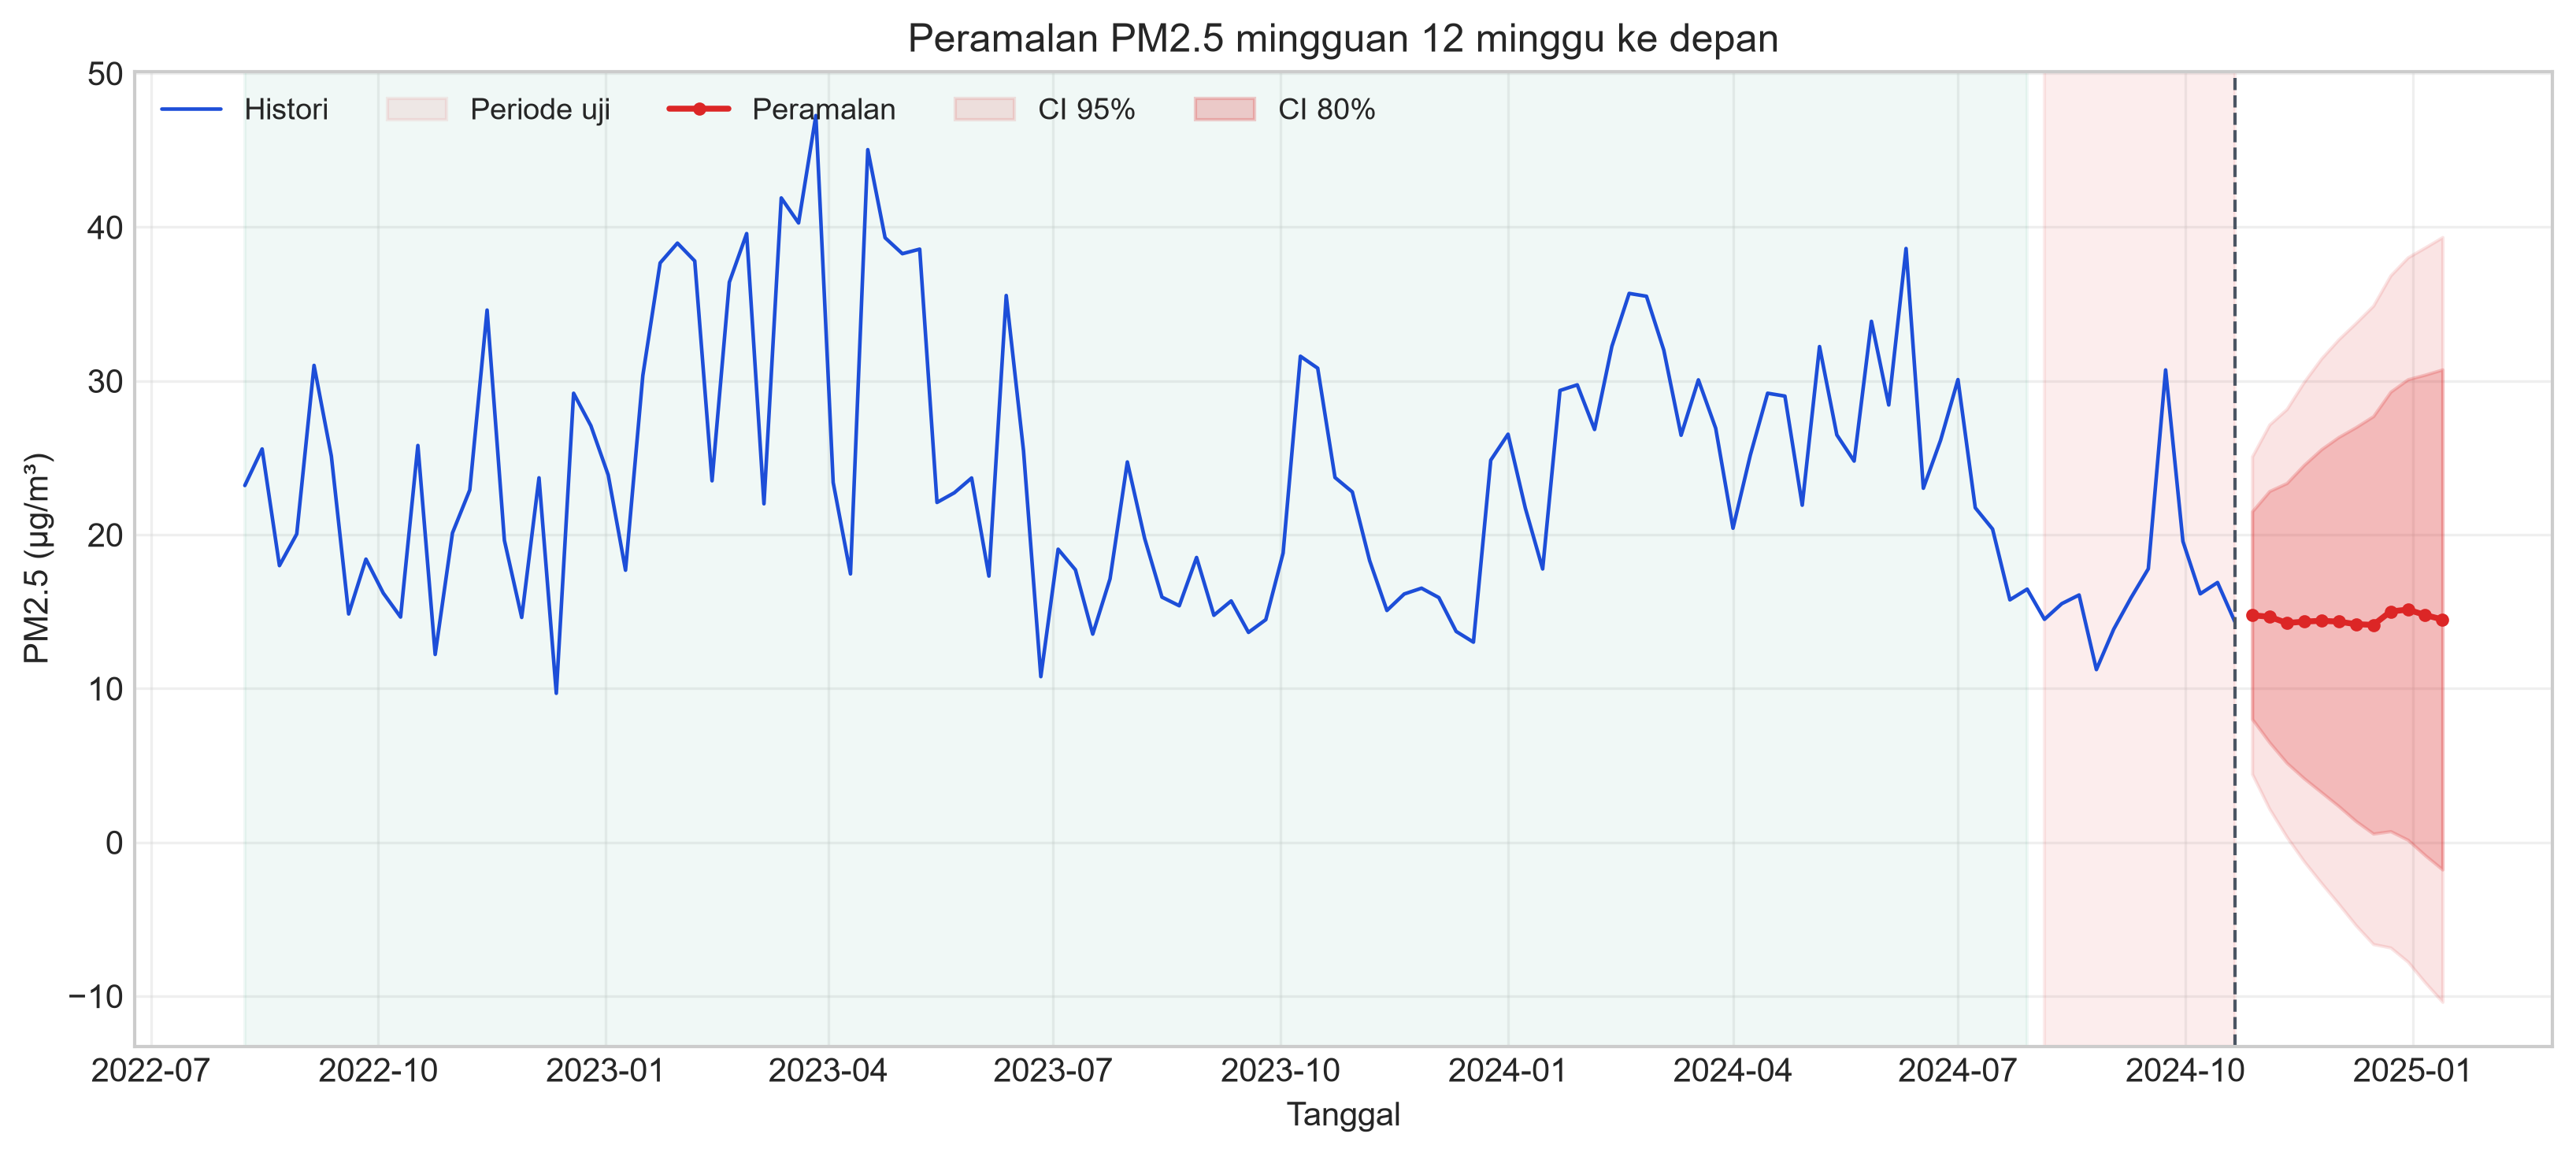

In [10]:
peramalan = pd.read_csv(ROOT / "outputs" / "tables" / "forecast.csv")
display(peramalan.round(2))
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig09_forecast.png"), width=950))


## 10. Kesimpulan dan keterbatasan

- Data CAMS/Open-Meteo adalah **grid model**, bukan stasiun darat Surakarta.
- Hanya 116 minggu (~2,2 siklus tahunan) yang homogen; estimasi musiman rapuh.
- Model terbaik menurut AICc adalah SARIMA(2,1,0)(1,0,0)[52], tetapi performa ujinya
  tidak berbeda signifikan dari naive random walk.
- Suku AR musiman tidak signifikan dan residual heteroskedastik.
- Peramalan 12 minggu sebaiknya dibaca sebagai skenario, bukan prediksi presisi tinggi.

Output lengkap: `outputs/tables/`, `outputs/figures/`, `outputs/results.json`, dan
`outputs/Hasil_Analisis_PM25_Surakarta.xlsx`.
